# Visualize filters

Applies every filter of `filter/` to **one image and its ROI** and shows how the filter changes the image:

* row 1: the axial slice with the most ROI voxels (orange contour = ROI), raw image first,
* row 2: the same slice inside the ROI only (zoomed to the ROI),
* row 3: histogram of the ROI voxel values (the values the features are computed from),
* a table of ROI statistics, including the correlation of each filtered image with the raw image
  (≈ 1 → the filter barely changes the information, ≈ 0 → it shows something new).

The images are produced exactly as in the feature extraction: PyRadiomics pre-processing
(normalize → resample to 1 mm → crop around the ROI) followed by the PyRadiomics filter generators.


In [1]:
import sys
import logging
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import radiomics
from IPython.display import display

radiomics.setVerbosity(logging.ERROR)          # hide the 'fixed bin count' warnings
from pipeline import *                         # also registers the custom Gabor / Laws image types

params = load_params()
print("PyRadiomics", radiomics.__version__, "| image types:", radiomics.getImageTypes())

PyRadiomics 3.1.1.dev111+g8ed579383 | image types: ['Exponential', 'Gradient', 'LBP2D', 'LBP3D', 'LoG', 'Logarithm', 'Original', 'Square', 'SquareRoot', 'Wavelet']


In [2]:
display(filter_table(params))

,filter,csv,pyradiomics_image_type,custom,enabled,args
0,raw_image,features_raw_image.csv,Original,False,True,{}
1,binary_patterns,features_binary_patterns.csv,LBP3D,False,True,"{'lbp3DLevels': 2, 'lbp3DIcosphereRadius': 1, ..."
2,gradient_filter,features_gradient_filter.csv,Gradient,False,True,{'gradientUseSpacing': True}
3,log_filter,features_log_filter.csv,LoG,False,True,"{'sigma': [1.0, 2.0, 3.0, 4.0, 5.0]}"
4,wavelet_filter,features_wavelet_filter.csv,Wavelet,False,True,"{'wavelet': 'coif1', 'level': 1, 'start_level'..."
5,square_filter,features_square_filter.csv,Square,False,True,{}
6,square_root_filter,features_square_root_filter.csv,SquareRoot,False,True,{}
7,logarithmic_filter,features_logarithmic_filter.csv,Logarithm,False,True,{}
8,exponential_filter,features_exponential_filter.csv,Exponential,False,True,{}
9,gabor_filter,features_gabor_filter.csv,Gabor,True,True,"{'gaborSigma': [2.0, 4.0], 'gaborLambda': [4.0..."


## Choose the image and ROI
`TASK = (case, side, channel)`. Pre-processing options (registration / bias correction) come from
`setup.yaml → PIPELINE_OPTIONS` unless set in `pyradiomics_params.yaml`.

options: {'registration': True, 'bias_correction': False}
pre-processed grid (x, y, z): (117, 136, 117) | spacing: (1.0, 1.0, 1.0) | ROI voxels: 65965


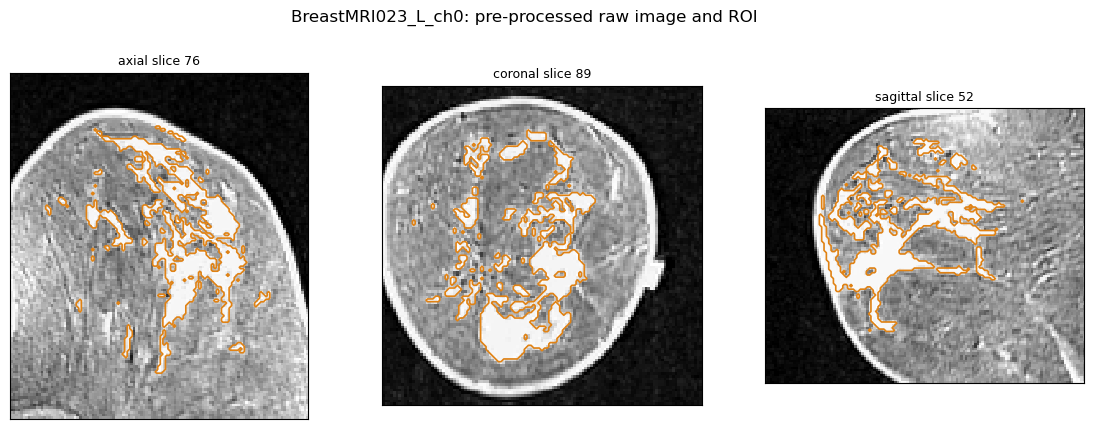

In [3]:
TASK = ("BreastMRI023", "L", 0)
SAVE_DIR = params["figure_dir"]

extractor = make_extractor(params)
pre = preprocess_task(TASK, params, extractor)
print("options:", params["options"])
print("pre-processed grid (x, y, z):", pre["image"].GetSize(), "| spacing:", pre["image"].GetSpacing(),
      "| ROI voxels:", int(pre["mask_array"].sum()))

from visualize import show_image_with_mask
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, axis, plane in zip(axes, (0, 1, 2), ("axial", "coronal", "sagittal")):
    index = largest_slice_index(pre["mask_array"], axis)
    show_image_with_mask(ax, pre["image_array"], pre["mask_array"], pre["spacing_zyx"], axis, index,
                         title=f"{plane} slice {index}")
fig.suptitle(f"{task_name(*TASK)}: pre-processed raw image and ROI", y=1.02)
plt.show()

all_arrays = {}

## Raw image (`raw_image.py`, PyRadiomics `Original`)
No filter: the normalized (z-score × 100, clipped at ±3 SD) and 1 mm resampled image. Every other filter is
applied to exactly this image.

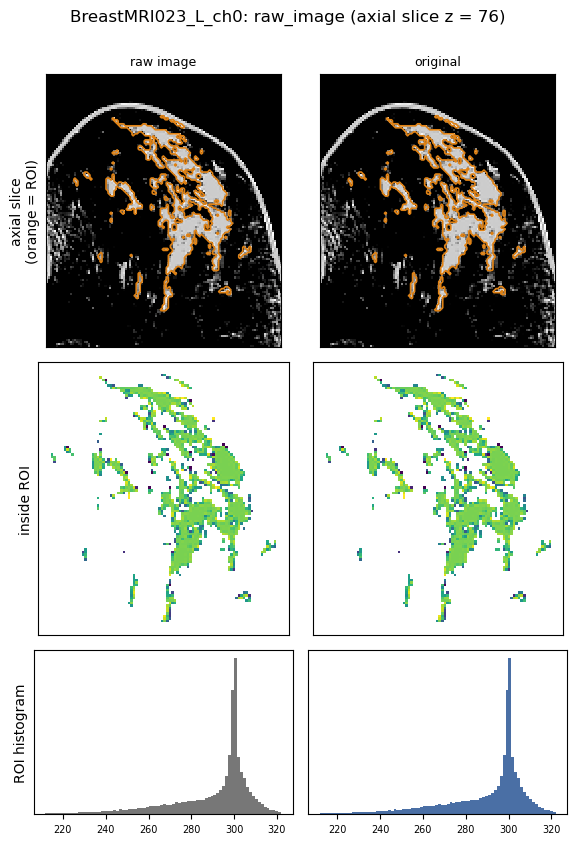

,image,min,p01,mean,p99,max,std,corr_with_raw
0,original,106.445,211.83,289.405,321.998,352.792,22.073,1.0


In [4]:
arrays = filter_arrays("raw_image", pre, params)
all_arrays["raw_image"] = arrays
show_filter("raw_image", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Local binary patterns 3D (`binary_patterns.py`, PyRadiomics `LBP3D`)
Around every ROI voxel the image is sampled on an icosphere (radius 1 mm, 42 points) and each sample is set to
1 if it is ≥ the centre value. The binary pattern is expanded in spherical harmonics:
`lbp-3D-m1` / `lbp-3D-m2` are the energies of degree 0 / 1 (rotation invariant), `lbp-3D-k` is the kurtosis
of the sampled values. Maps exist only inside the ROI (0 outside).

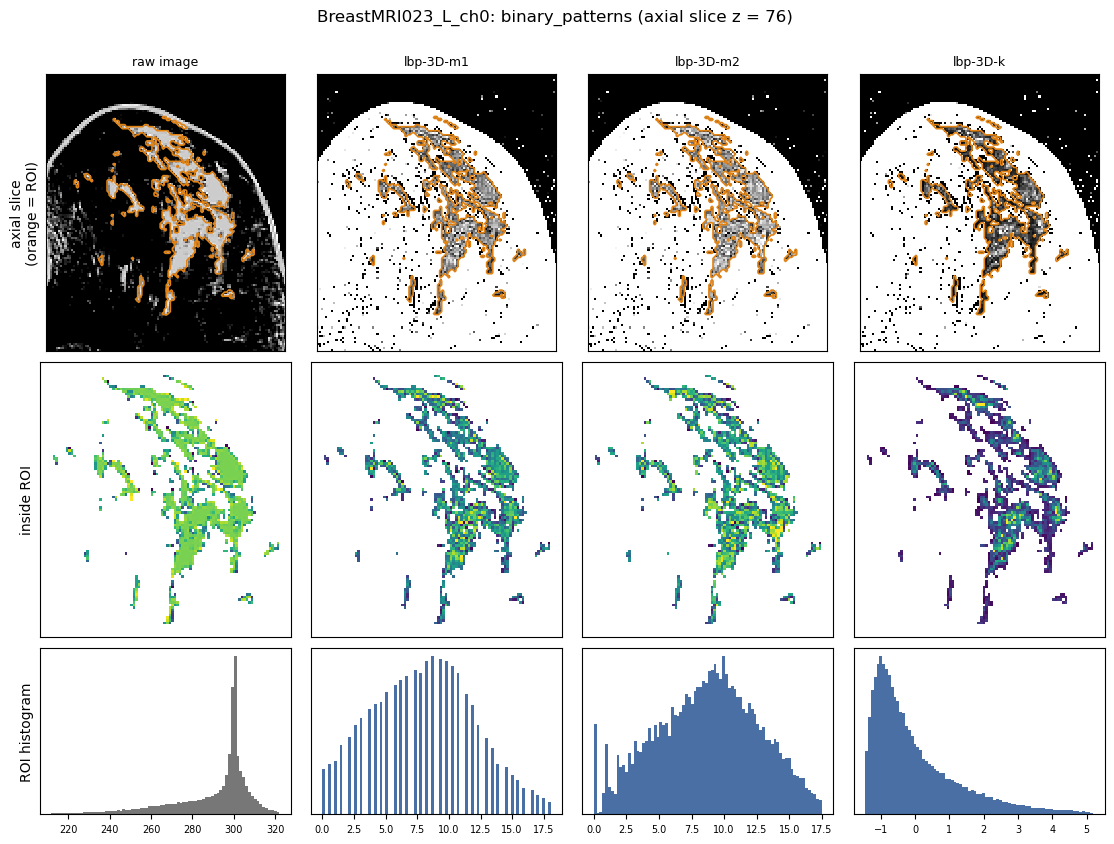

,image,min,p01,mean,p99,max,std,corr_with_raw
0,lbp-3D-m1,0.000,0.000,8.076,18.050,21.660,4.168,-0.321
1,lbp-3D-m2,0.000,0.000,8.839,17.515,19.805,4.013,-0.341
2,lbp-3D-k,-1.645,-1.463,0.076,5.199,18.752,1.456,0.332


In [5]:
arrays = filter_arrays("binary_patterns", pre, params)
all_arrays["binary_patterns"] = arrays
show_filter("binary_patterns", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Gradient magnitude (`gradient_filter.py`, PyRadiomics `Gradient`)
$\|\nabla I\| = \sqrt{I_x^2 + I_y^2 + I_z^2}$ with central differences (per mm). Edges (e.g. fibroglandular
tissue / fat borders) become bright, homogeneous regions dark.

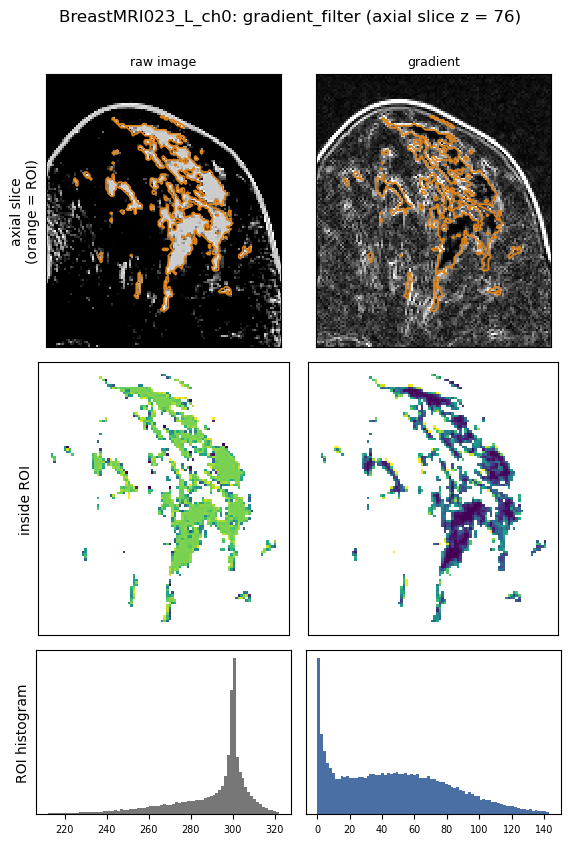

,image,min,p01,mean,p99,max,std,corr_with_raw
0,gradient,0.0,0.11,48.783,142.961,221.024,36.037,-0.503


In [6]:
arrays = filter_arrays("gradient_filter", pre, params)
all_arrays["gradient_filter"] = arrays
show_filter("gradient_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Laplacian of Gaussian (`log_filter.py`, PyRadiomics `LoG`)
$\mathrm{LoG}_\sigma[I] = \sigma^2 \nabla^2 (G_\sigma * I)$. Bright blobs of radius ≈ σ√3 mm give strongly
negative values, dark blobs positive values. Small σ → fine texture, large σ → coarse structures.

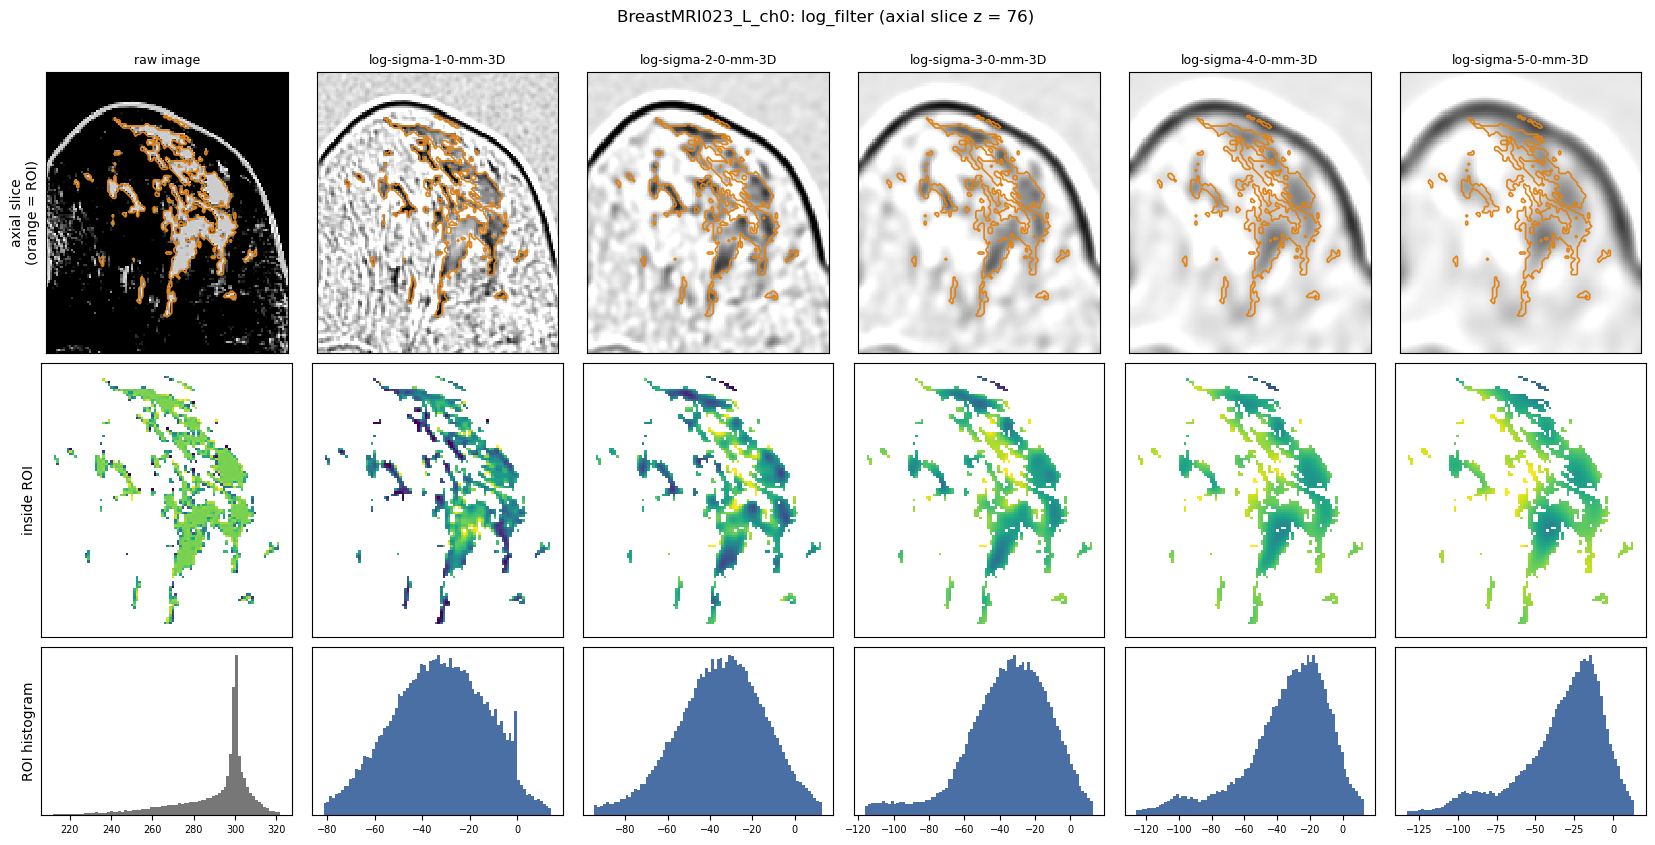

,image,min,p01,mean,p99,max,std,corr_with_raw
0,log-sigma-1-0-mm-3D,-115.072,-81.618,-32.670,14.461,73.153,20.999,-0.416
1,log-sigma-2-0-mm-3D,-130.309,-94.621,-34.918,12.948,53.582,22.183,-0.325
2,log-sigma-3-0-mm-3D,-147.441,-116.181,-35.611,12.618,44.820,25.952,-0.248
3,log-sigma-4-0-mm-3D,-158.493,-126.270,-34.700,12.803,41.450,28.667,-0.198
4,log-sigma-5-0-mm-3D,-165.649,-132.908,-34.191,13.623,38.911,30.446,-0.166


In [7]:
arrays = filter_arrays("log_filter", pre, params)
all_arrays["log_filter"] = arrays
show_filter("log_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Wavelet (`wavelet_filter.py`, PyRadiomics `Wavelet`, coif1, level 1)
Undecimated wavelet transform: the low-pass (L) or high-pass (H) coif1 filter along x, y and z gives 8
sub-bands of the same size as the image. `LLL` is a smoothed image; every `H` adds detail (edges) along
that axis.

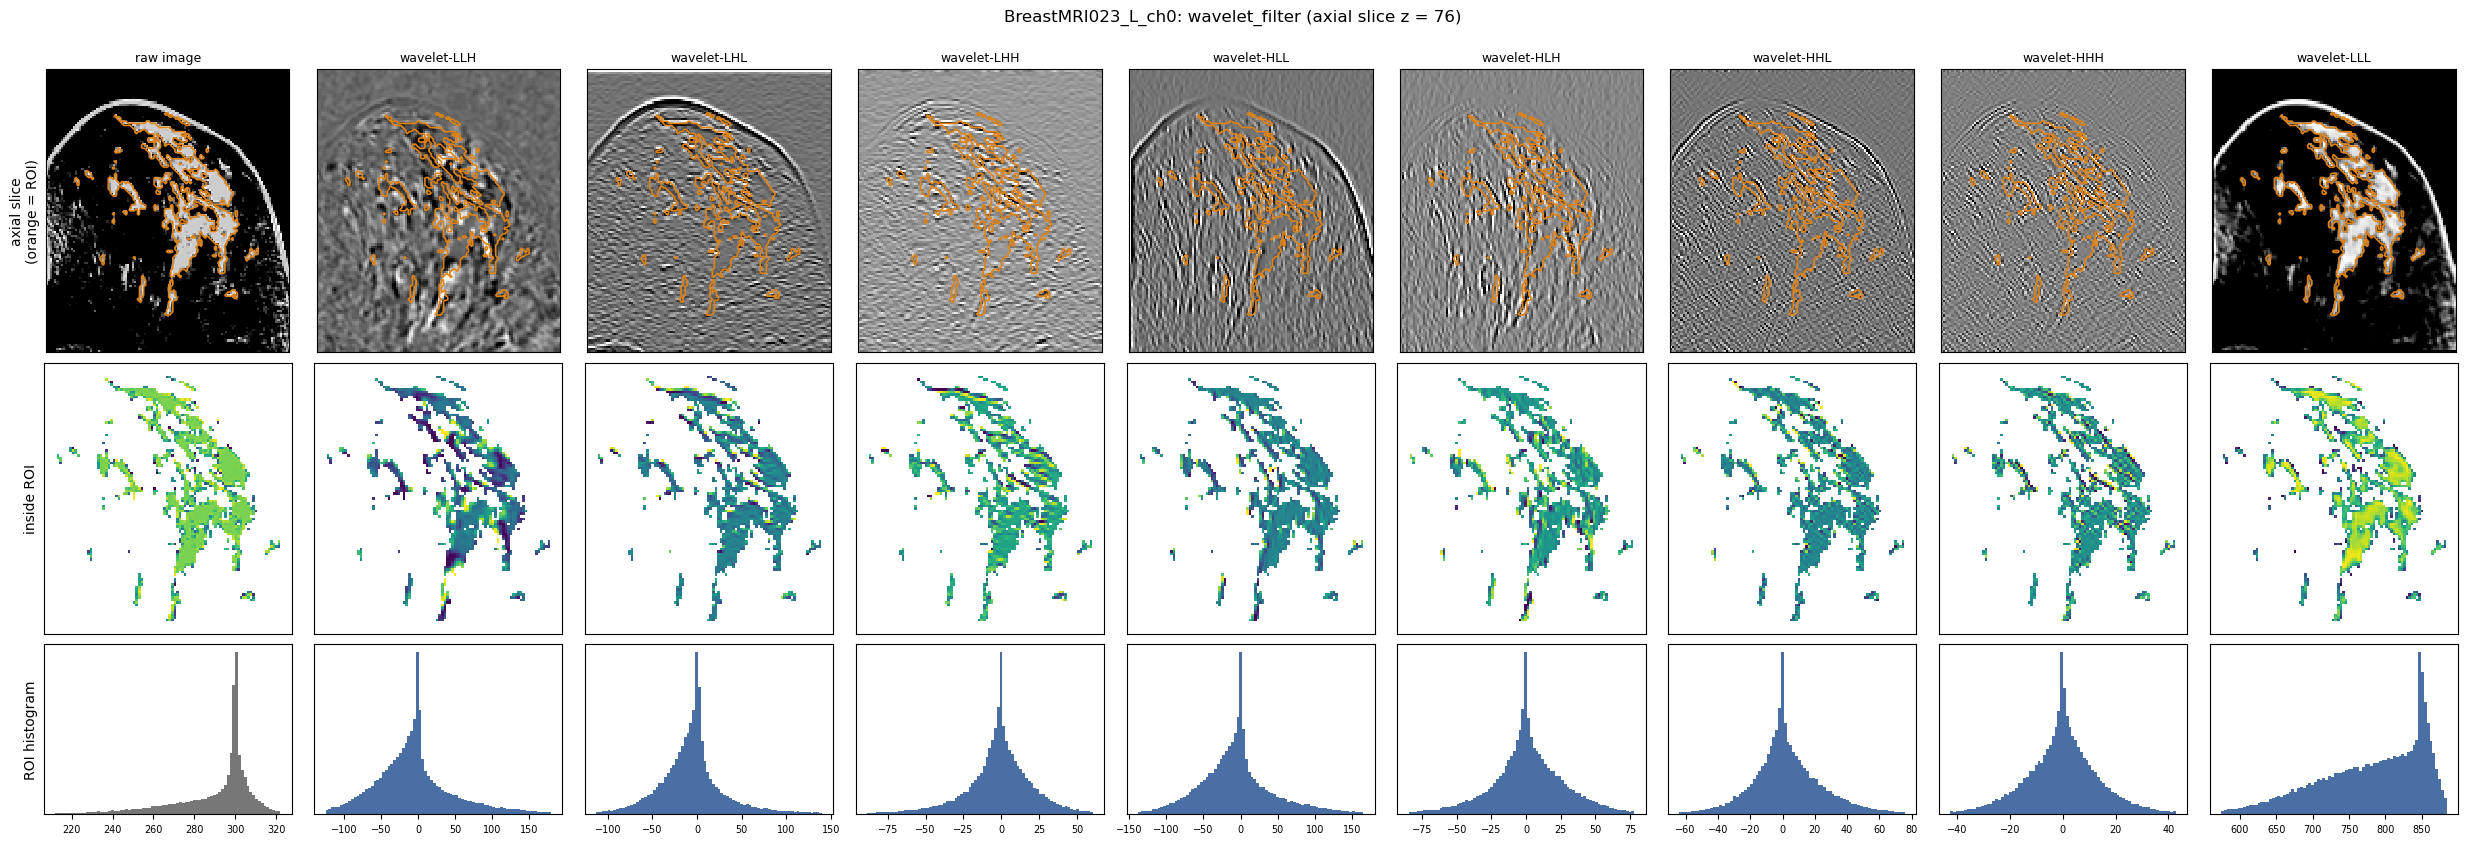

,image,min,p01,mean,p99,max,std,corr_with_raw
0,wavelet-LLH,-205.861,-125.055,-4.500,179.888,322.340,57.471,-0.050
1,wavelet-LHL,-230.108,-112.801,-5.319,139.783,316.532,42.477,-0.056
2,wavelet-LHH,-213.829,-88.671,-2.289,60.407,168.035,25.873,-0.059
3,wavelet-HLL,-313.282,-138.176,-5.038,164.969,399.163,56.136,0.000
4,wavelet-HLH,-208.777,-84.763,1.011,78.011,178.266,29.851,-0.002
5,wavelet-HHL,-162.238,-63.843,2.903,75.845,154.614,24.924,0.037
6,wavelet-HHH,-99.557,-42.701,-0.089,42.829,115.278,15.728,-0.012
7,wavelet-LLL,399.367,573.990,779.465,884.169,924.442,75.327,0.716


In [8]:
arrays = filter_arrays("wavelet_filter", pre, params)
all_arrays["wavelet_filter"] = arrays
show_filter("wavelet_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Square (`square_filter.py`, PyRadiomics `Square`)
$f(x) = (x/\sqrt{M})^2$, $M = \max|x|$ over the whole grid. Emphasizes bright voxels; negative values
become positive.

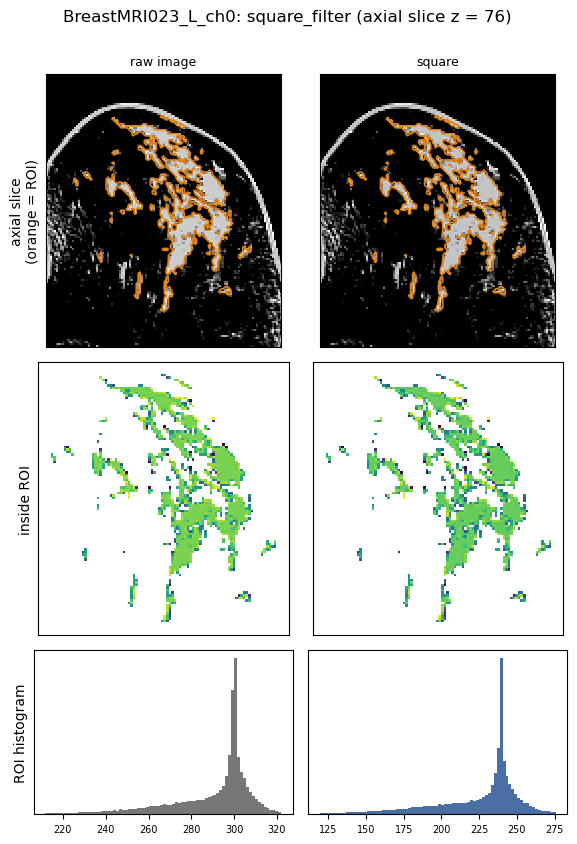

,image,min,p01,mean,p99,max,std,corr_with_raw
0,square,30.131,119.328,224.025,275.723,330.98,31.725,0.997


In [9]:
arrays = filter_arrays("square_filter", pre, params)
all_arrays["square_filter"] = arrays
show_filter("square_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Square root (`square_root_filter.py`, PyRadiomics `SquareRoot`)
$f(x) = \operatorname{sign}(x)\sqrt{M|x|}$. Compresses bright values and spreads out dark ones.

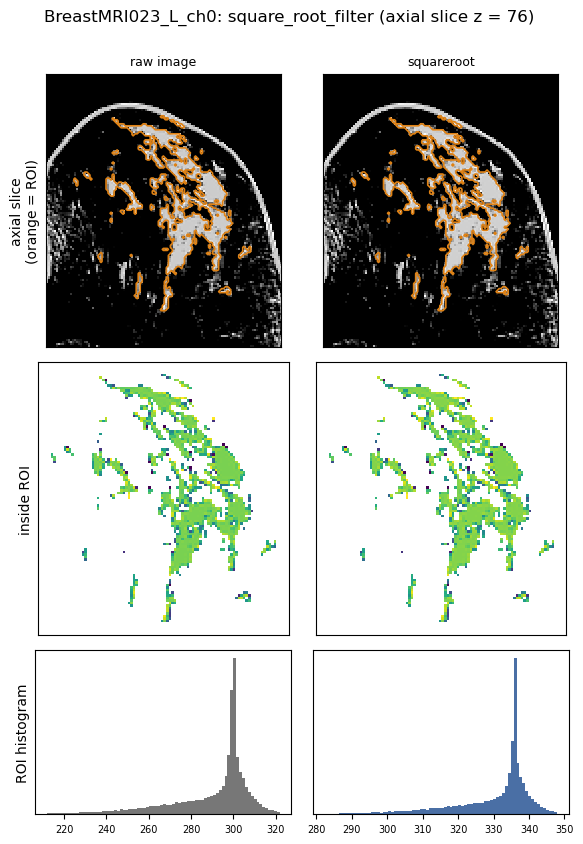

,image,min,p01,mean,p99,max,std,corr_with_raw
0,squareroot,200.069,282.235,329.63,347.972,364.23,13.107,0.999


In [10]:
arrays = filter_arrays("square_root_filter", pre, params)
all_arrays["square_root_filter"] = arrays
show_filter("square_root_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Logarithm (`logarithmic_filter.py`, PyRadiomics `Logarithm`)
$f(x) = \operatorname{sign}(x)\log(|x| + 1)\cdot M/\log(M + 1)$. Strong compression of bright values.

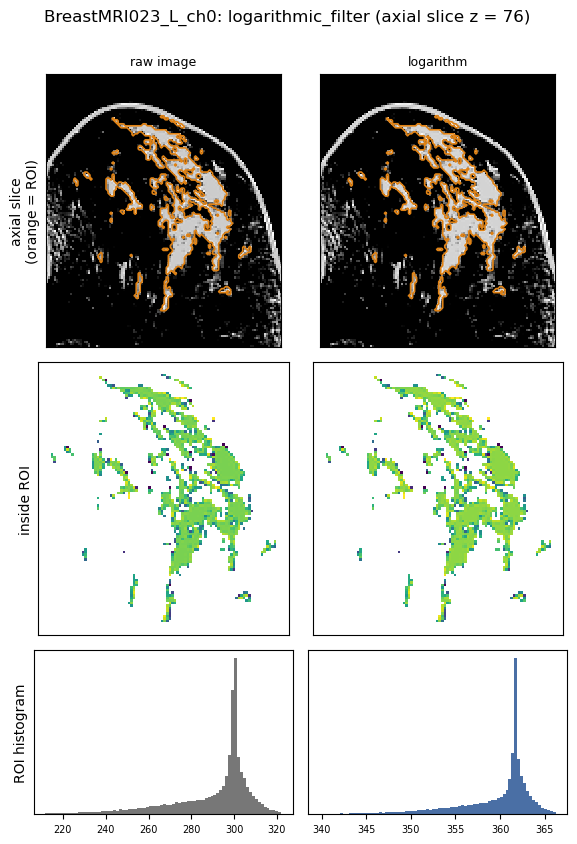

,image,min,p01,mean,p99,max,std,corr_with_raw
0,logarithm,296.465,339.791,359.286,366.234,372.006,5.256,0.997


In [11]:
arrays = filter_arrays("logarithmic_filter", pre, params)
all_arrays["logarithmic_filter"] = arrays
show_filter("logarithmic_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Exponential (`exponential_filter.py`, PyRadiomics `Exponential`)
$f(x) = e^{c x}$, $c = \log(M)/M$. Strong expansion of bright values: only the brightest voxels keep
contrast.

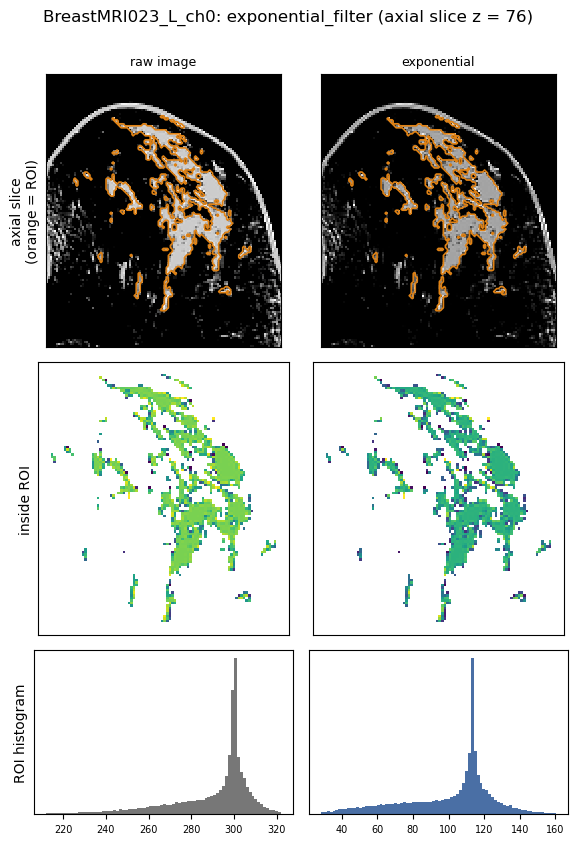

,image,min,p01,mean,p99,max,std,corr_with_raw
0,exponential,5.358,28.228,100.861,160.376,260.628,27.535,0.967


In [12]:
arrays = filter_arrays("exponential_filter", pre, params)
all_arrays["exponential_filter"] = arrays
show_filter("exponential_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Gabor (`gabor_filter.py`, custom image type `Gabor`)
Not built into PyRadiomics; implemented following the IBSI 2 definition and registered as a PyRadiomics image
type. A complex sinusoid of wavelength λ under a Gaussian envelope (σ, aspect ratio γ), applied slice by slice
in the axial plane:

$$h(u,v) = \frac{\gamma}{2\pi\sigma^2}\, e^{-(u'^2 + \gamma^2 v'^2)/(2\sigma^2)}\, e^{i 2\pi u'/\lambda},
\quad u' = u\cos\theta + v\sin\theta,\; v' = -u\sin\theta + v\cos\theta$$

The response map is $|I * h|$ averaged over 8 orientations θ (rotation invariance). Large values = stripes
or edges with a period of ≈ λ mm. When σ is small compared to λ the kernel is not zero-mean, so part of the
plain image intensity leaks into the response (e.g. σ = 2 mm, λ = 8 mm).

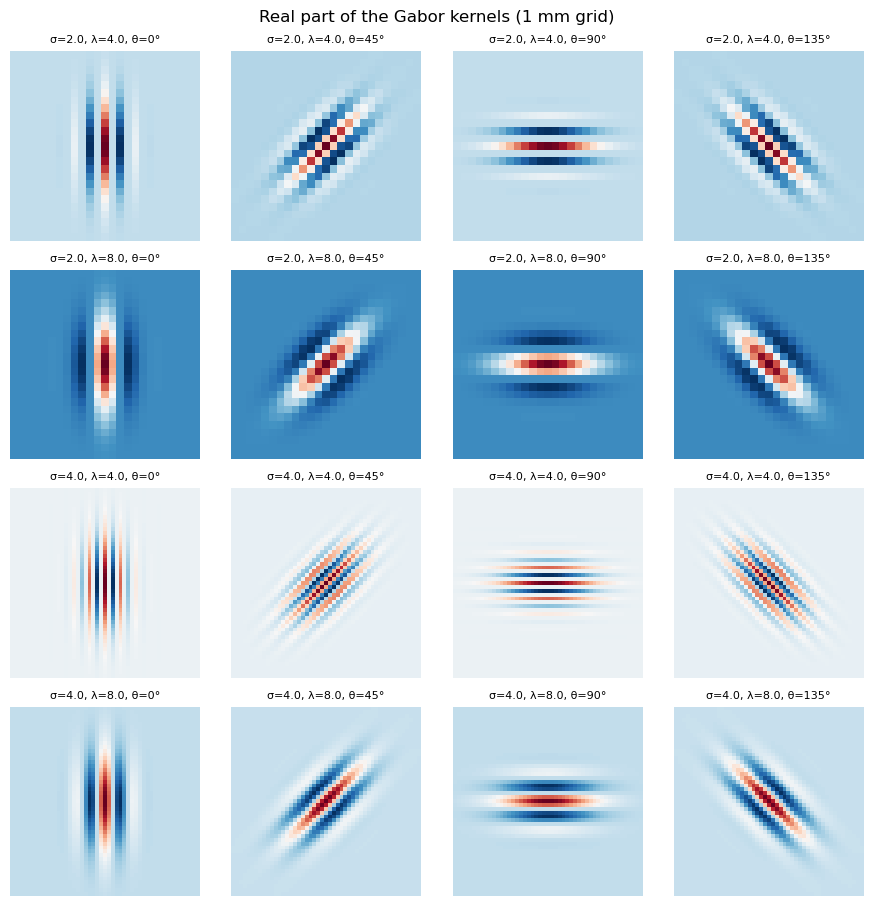

In [13]:
from filter.gabor_filter import gabor_kernel
args = filter_args("gabor_filter", params["filters"]["gabor_filter"]["args"])
pairs = [(s, l) for s in args["gaborSigma"] for l in args["gaborLambda"]]
fig, axes = plt.subplots(len(pairs), 4, figsize=(9, 2.3 * len(pairs)), squeeze=False)
for row, (sigma, wavelength) in enumerate(pairs):
    for col, theta in enumerate(np.arange(4) * np.pi / 4):
        kernel = gabor_kernel(sigma, wavelength, args["gaborGamma"], theta, (1.0, 1.0), args["gaborTruncate"])
        axes[row, col].imshow(kernel.real, cmap="RdBu_r")
        axes[row, col].set_title(f"σ={sigma}, λ={wavelength}, θ={np.degrees(theta):.0f}°", fontsize=8)
        axes[row, col].axis("off")
fig.suptitle("Real part of the Gabor kernels (1 mm grid)")
fig.tight_layout()
plt.show()

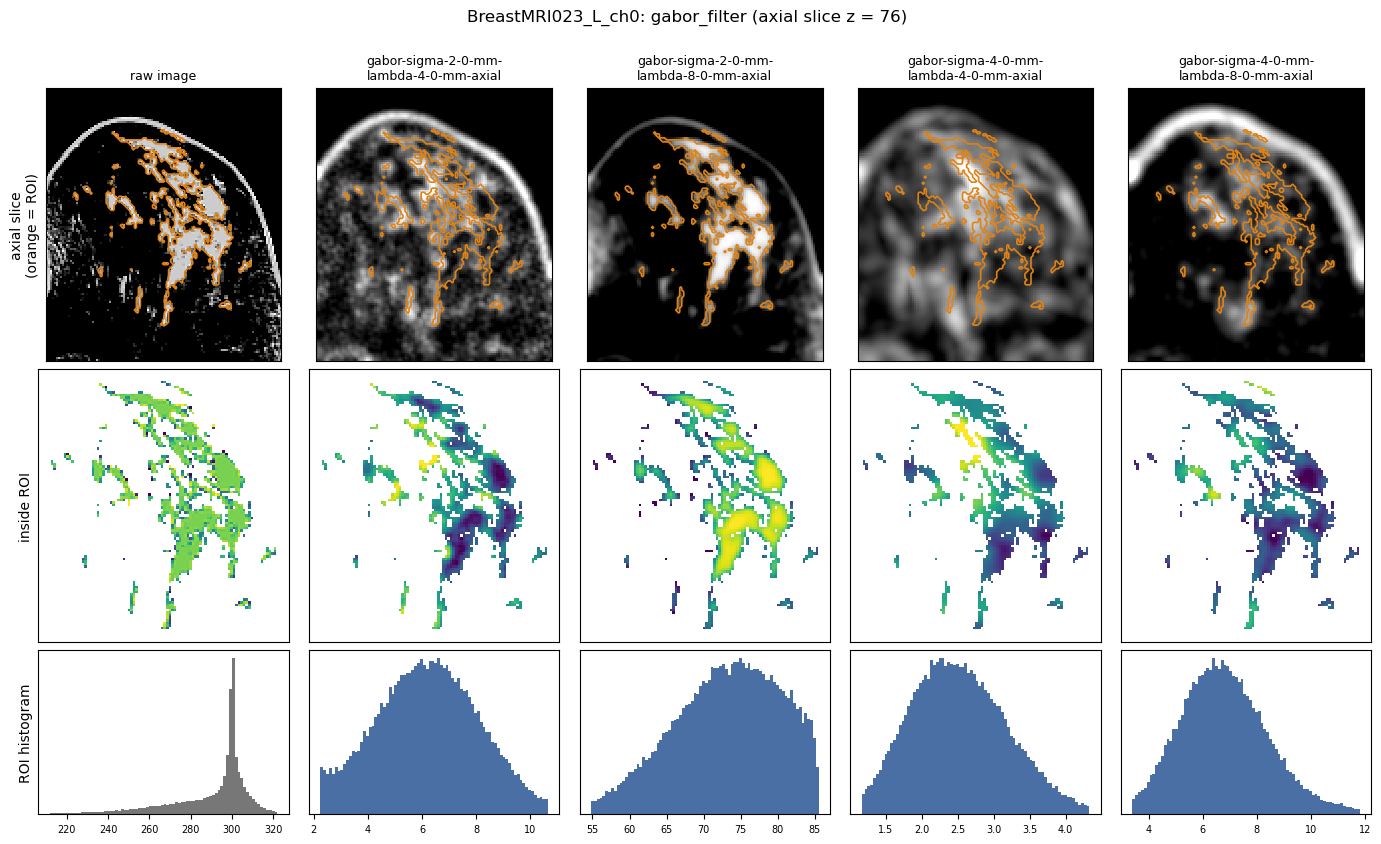

,image,min,p01,mean,p99,max,std,corr_with_raw
0,gabor-sigma-2-0-mm-lambda-4-0-mm-axial,1.711,2.245,6.219,10.664,13.962,1.932,-0.078
1,gabor-sigma-2-0-mm-lambda-8-0-mm-axial,42.609,54.815,73.103,85.542,86.887,7.372,0.418
2,gabor-sigma-4-0-mm-lambda-4-0-mm-axial,0.726,1.166,2.536,4.331,5.636,0.692,-0.083
3,gabor-sigma-4-0-mm-lambda-8-0-mm-axial,1.795,3.397,6.850,11.825,15.395,1.724,0.109


In [14]:
arrays = filter_arrays("gabor_filter", pre, params)
all_arrays["gabor_filter"] = arrays
show_filter("gabor_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## Laws texture energy (`laws_filter.py`, custom image type `Laws`)
Not built into PyRadiomics; implemented following IBSI 2 and registered as a PyRadiomics image type.
Separable 3D kernels from the 1D kernels L5 (level), E5 (edge), S5 (spot), W5 (wave) and R5 (ripple); the name
gives the kernel along x, y, z. The response is pooled (max) over the 24 right-angle rotations of the kernel
(rotation invariance), then turned into **energy** = local mean of |response| in a 15×15×15 voxel box.

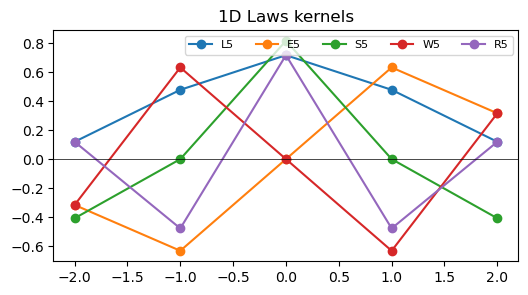

In [15]:
from filter.laws_filter import LAWS_1D
fig, ax = plt.subplots(figsize=(6, 3))
for kernel_name in ("L5", "E5", "S5", "W5", "R5"):
    ax.plot(range(-2, 3), LAWS_1D[kernel_name], marker="o", label=kernel_name)
ax.axhline(0, color="k", lw=0.5)
ax.set_title("1D Laws kernels")
ax.legend(ncol=5, fontsize=8)
plt.show()

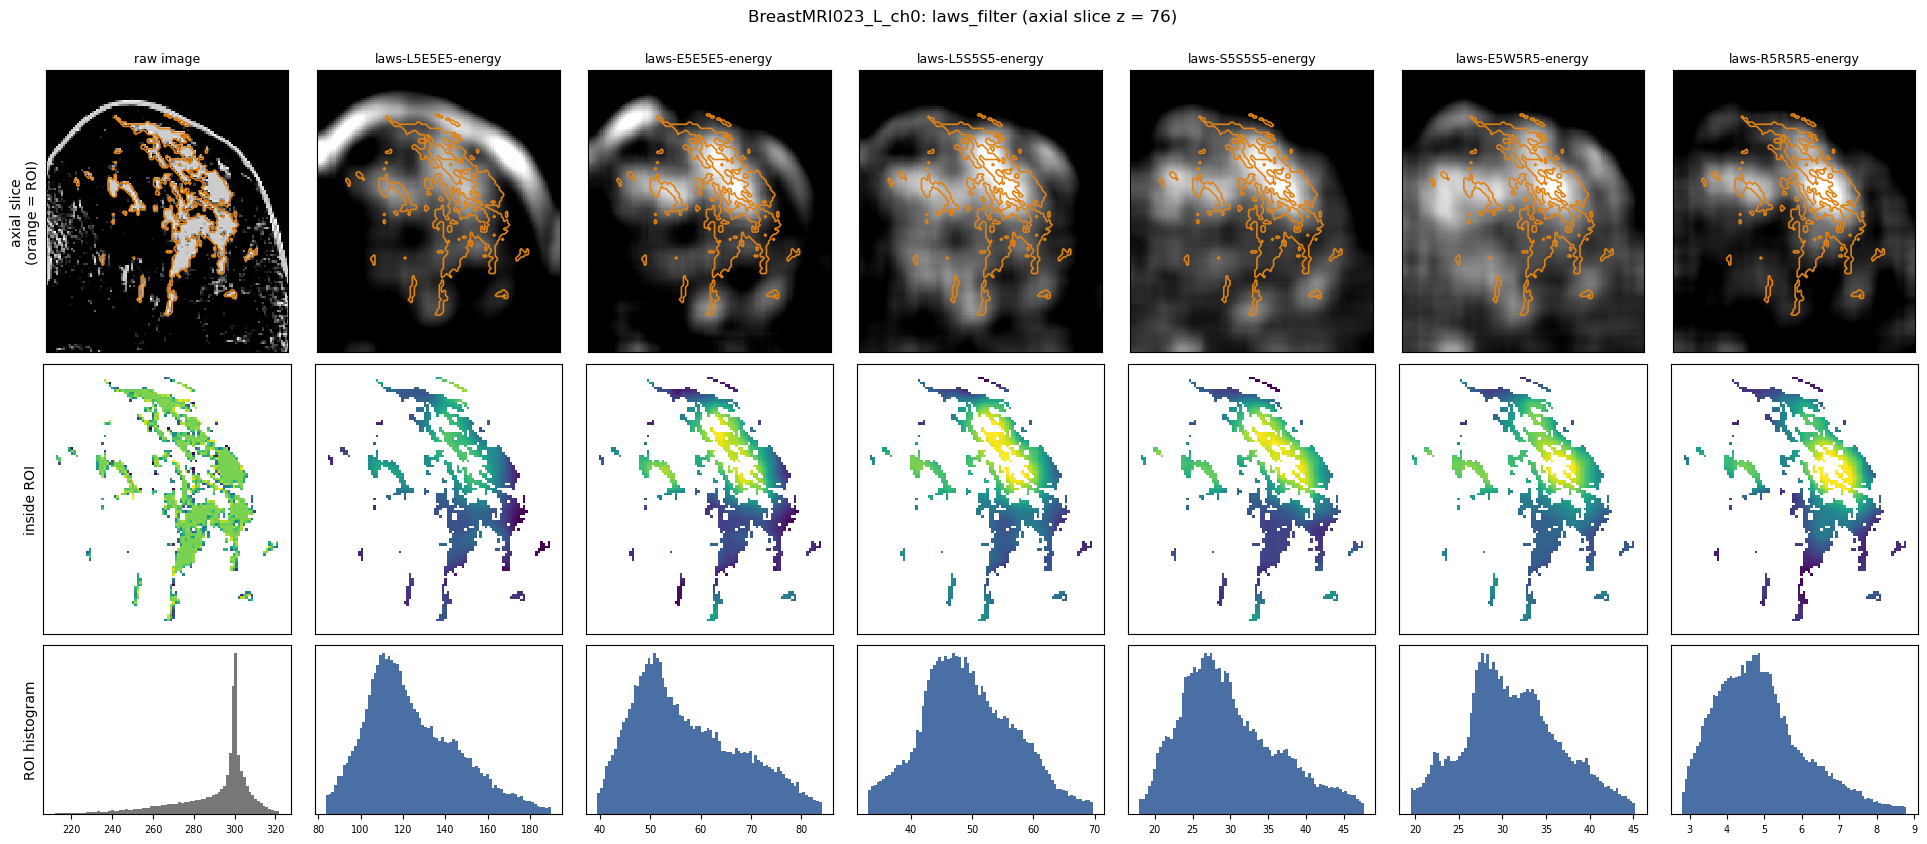

,image,min,p01,mean,p99,max,std,corr_with_raw
0,laws-L5E5E5-energy,72.858,83.683,124.718,189.544,215.520,23.024,0.016
1,laws-E5E5E5-energy,29.452,39.394,57.422,84.030,102.523,10.925,-0.036
2,laws-L5S5S5-energy,25.385,33.019,49.519,69.727,75.287,7.993,-0.070
3,laws-S5S5S5-energy,13.550,17.965,30.051,47.723,53.084,6.797,-0.066
4,laws-E5W5R5-energy,15.438,19.461,31.187,45.241,51.335,5.805,-0.078
5,laws-R5R5R5-energy,1.938,2.789,4.936,8.796,12.056,1.296,-0.019


In [16]:
arrays = filter_arrays("laws_filter", pre, params)
all_arrays["laws_filter"] = arrays
show_filter("laws_filter", arrays, pre, save_dir=SAVE_DIR)
plt.show()
display(roi_statistics(arrays, pre).round(3))

## All filtered images
One axial slice of every image type that features are extracted from (window = 1st–99th percentile in the ROI).

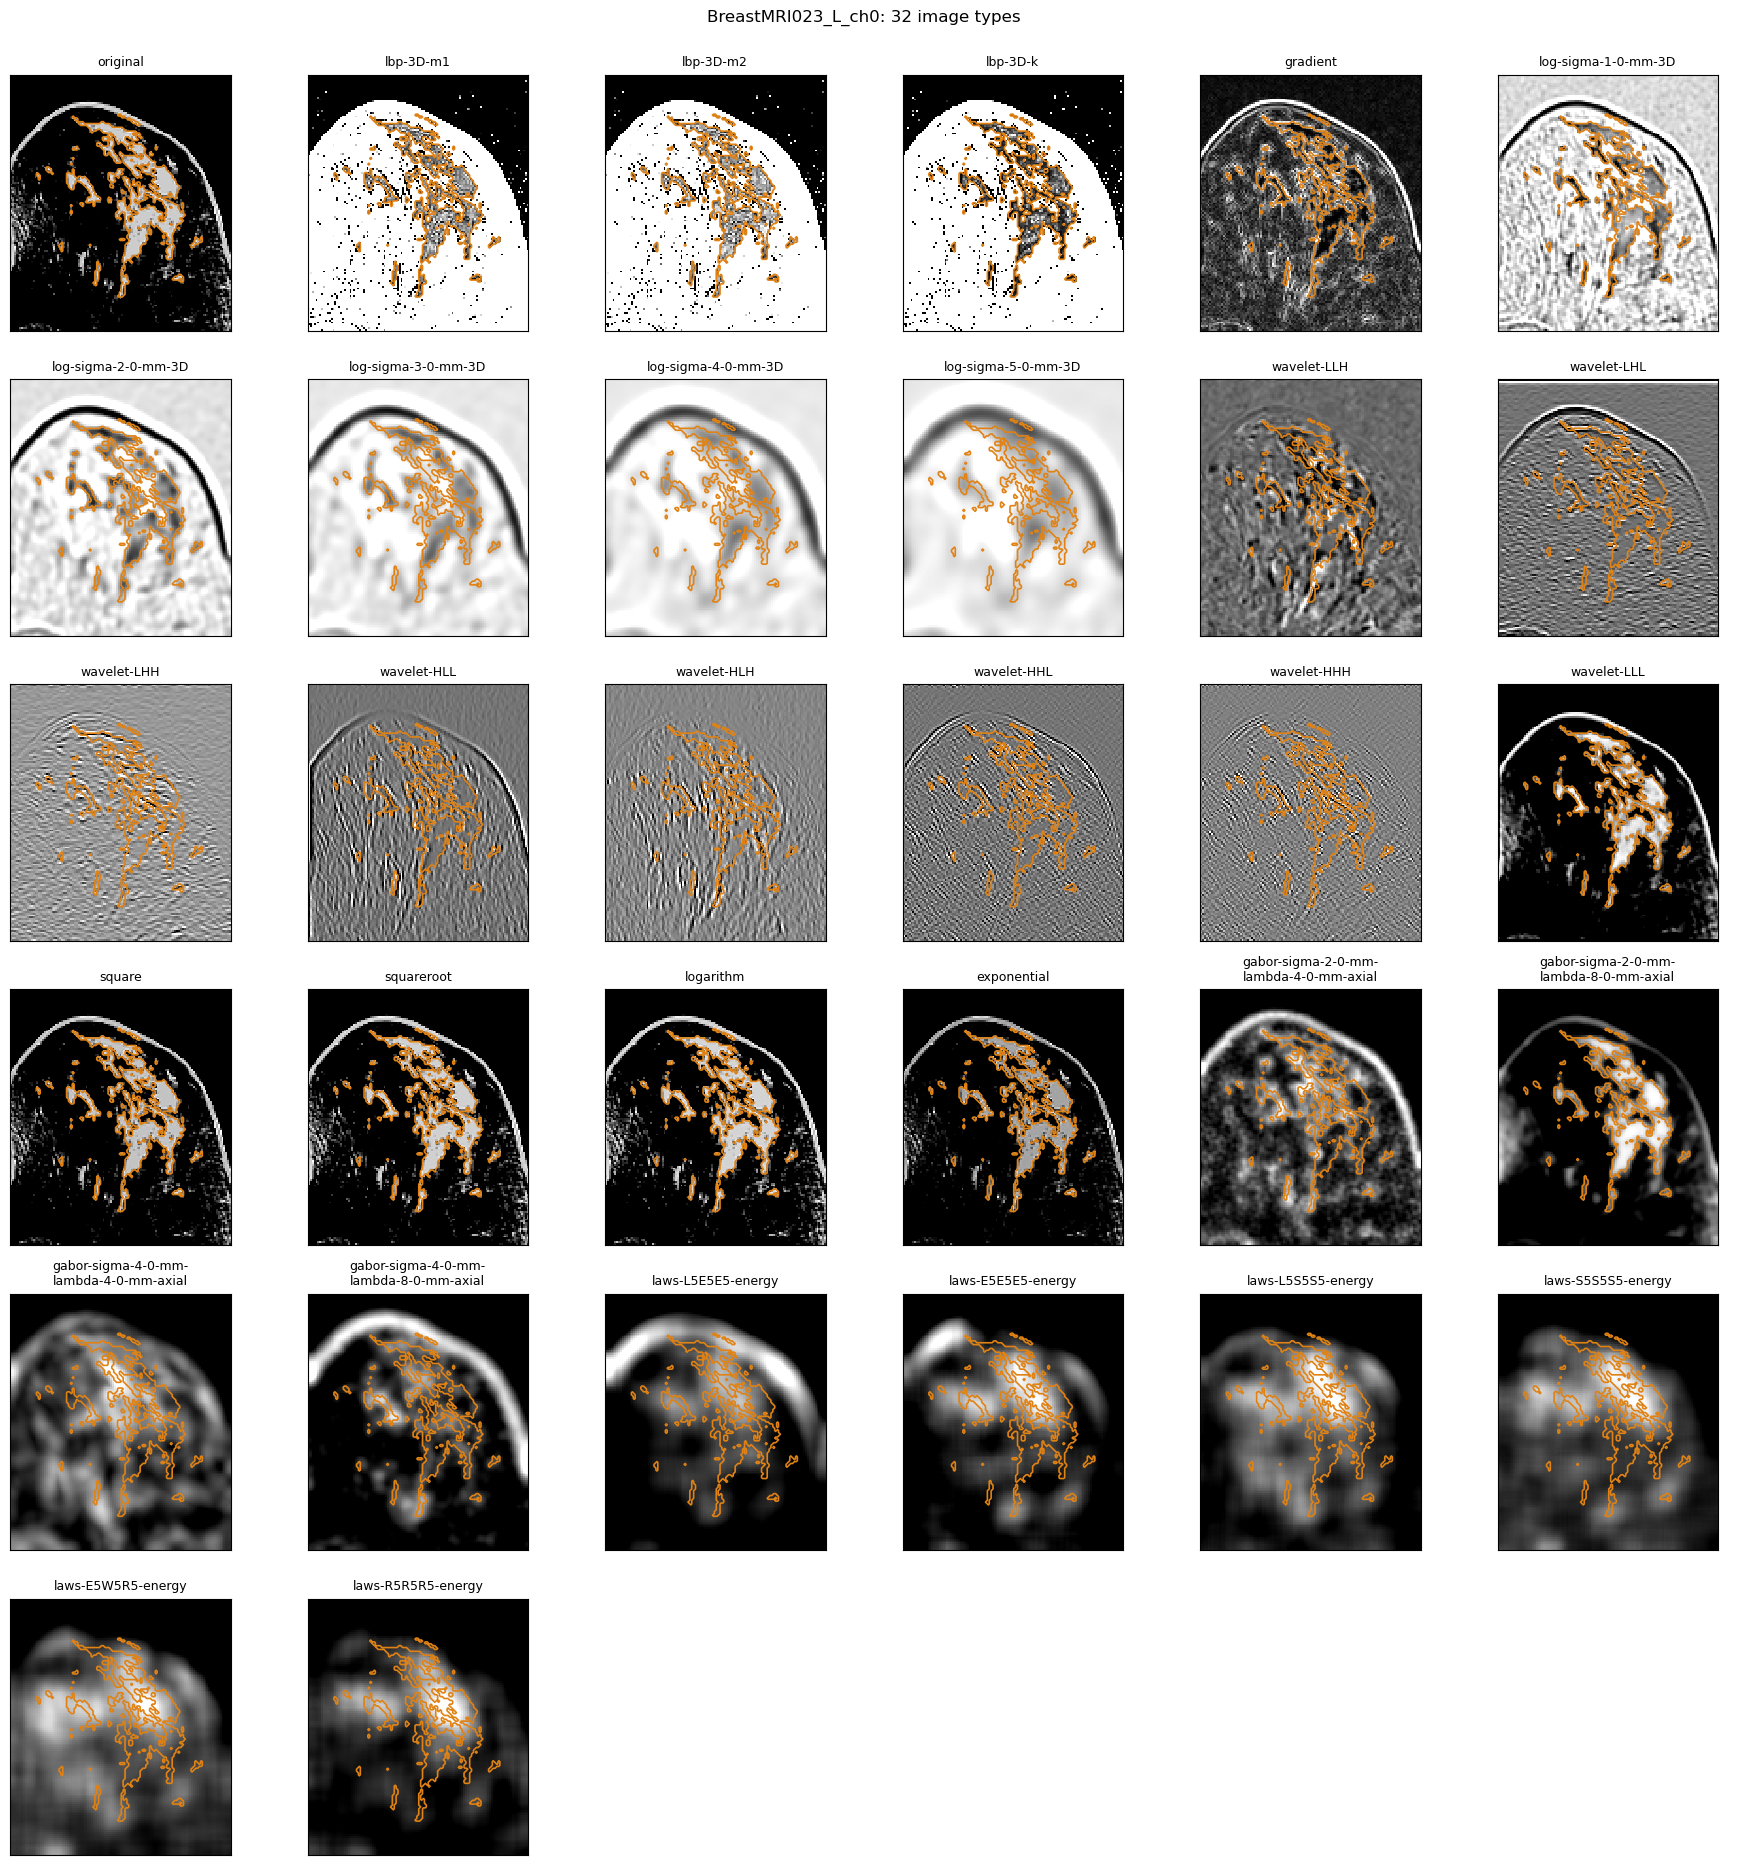

min      p01  \
filter             image                                                      
raw_image          original                                106.445  211.830   
binary_patterns    lbp-3D-m1                                 0.000    0.000   
                   lbp-3D-m2                                 0.000    0.000   
                   lbp-3D-k                                 -1.645   -1.463   
gradient_filter    gradient                                  0.000    0.110   
log_filter         log-sigma-1-0-mm-3D                    -115.072  -81.618   
                   log-sigma-2-0-mm-3D                    -130.309  -94.621   
                   log-sigma-3-0-mm-3D                    -147.441 -116.181   
                   log-sigma-4-0-mm-3D                    -158.493 -126.270   
                   log-sigma-5-0-mm-3D                    -165.649 -132.908   
wavelet_filter     wavelet-LLH                            -205.861 -125.055   
                   wavelet-LHL                            -230.108 -112.801   
                   wavelet-LHH                            -213.829  -88.671   
                   wavelet-HLL                            -313.282 -138.176   
                   wavelet-HLH                            -208.777  -84.763   
                   wavelet-HHL                            -162.238  -63.843   
                   wavelet-HHH                             -99.557  -42.701   
                   wavelet-LLL                             399.367  573.990   
square_filter      square                                   30.131  119.328   
square_root_filter squareroot                              200.069  282.235   
logarithmic_filter logarithm                               296.465  339.791   
exponential_filter exponential                               5.358   28.228   
gabor_filter       gabor-sigma-2-0-mm-lambda-4-0-mm-axial    1.711    2.245   
                   gabor-sigma-2-0-mm-lambda-8-0-mm-axial   42.609   54.815   
                   gabor-sigma-4-0-mm-lambda-4-0-mm-axial    0.726    1.166   
                   gabor-sigma-4-0-mm-lambda-8-0-mm-axial    1.795    3.397   
laws_filter        laws-L5E5E5-energy                       72.858   83.683   
                   laws-E5E5E5-energy                       29.452   39.394   
                   laws-L5S5S5-energy                       25.385   33.019   
                   laws-S5S5S5-energy                       13.550   17.965   
                   laws-E5W5R5-energy                       15.438   19.461   
                   laws-R5R5R5-energy                        1.938    2.789   

                                                              mean      p99  \
filter             image                                                      
raw_image          original                                289.405  321.998   
binary_patterns    lbp-3D-m1                                 8.076   18.050   
                   lbp-3D-m2                                 8.839   17.515   
                   lbp-3D-k                                  0.076    5.199   
gradient_filter    gradient                                 48.783  142.961   
log_filter         log-sigma-1-0-mm-3D                     -32.670   14.461   
                   log-sigma-2-0-mm-3D                     -34.918   12.948   
                   log-sigma-3-0-mm-3D                     -35.611   12.618   
                   log-sigma-4-0-mm-3D                     -34.700   12.803   
                   log-sigma-5-0-mm-3D                     -34.191   13.623   
wavelet_filter     wavelet-LLH                              -4.500  179.888   
                   wavelet-LHL                              -5.319  139.783   
                   wavelet-LHH                              -2.289   60.407   
                   wavelet-HLL                              -5.038  164.969   
                   wavelet-HLH                               1.011   78.011   
                   wavelet-HHL   

In [17]:
images = [(n, a) for arrays in all_arrays.values() for n, a in arrays.items()]   # 'original' = raw image
n_cols = 6
n_rows = int(np.ceil(len(images) / n_cols))
z = largest_slice_index(pre["mask_array"], 0)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3.1 * n_rows), squeeze=False)
for ax, (name, array) in zip(axes.ravel(), images):
    window = tuple(np.percentile(array[pre["mask_array"]], [1, 99]))
    show_image_with_mask(ax, array, pre["mask_array"], pre["spacing_zyx"], 0, z, title=wrap_title(name), window=window)
for ax in axes.ravel()[len(images):]:
    ax.axis("off")
fig.suptitle(f"{task_name(*TASK)}: {len(images)} image types", y=1.0)
fig.tight_layout()
Path(SAVE_DIR).mkdir(parents=True, exist_ok=True)
fig.savefig(Path(SAVE_DIR) / f"{task_name(*TASK)}_all_filters.png", dpi=80, bbox_inches="tight")
plt.show()

summary = pd.concat([roi_statistics(arrays, pre).assign(filter=name) for name, arrays in all_arrays.items()],
                    ignore_index=True)
display(summary.set_index(["filter", "image"]).round(3))